# Mixed-precision YOLOv8s on the VEK280 NPU with Vitis AI 6.1

This notebook takes the default COCO YOLOv8s (80 classes, 640 x 640 input) to the NPU of the AMD Versal VEK280
board as a **mixed-precision, full-NPU snapshot**: the backbone and the neck run in INT8, the head branches and the
decoding in BF16.

1. Import the model
2. Inspect it: which parts can run on the NPU?
3. Change the head so that the decoding runs on the NPU
4. Inspect the changed model
5. Quantize it (INT8 + BF16)
6. Compile it into a *snapshot* for the board

**Why mixed precision.** The YOLO decoding joins confidences (0 to 1) and box coordinates (0 to 640). One INT8 scale
for both loses the confidences. AMD's option 4 (*AI on Versal Edge Gen 2 with Vitis AI*, p. 15-16) keeps the
compute-heavy core in NPU INT8 and runs the low-compute, precision-sensitive part in NPU BF16. Here that part starts
earlier than in AMD's example: small objects need precise boxes, so the box branches run in BF16 from their first
convolution.

**How Vitis AI 6.1 works.** There is no separate quantizer or compiler tool. The Vitis AI software (**VAISW**) hooks
into ONNX Runtime: you run an ONNX model as usual, and VAISW uses the first images to calibrate, compiles the model for
the NPU and writes the snapshot. Environment variables (`VAISW_...`) control what it does.

The helpers are in `utils.py`; `vitis_ai/` holds the code that runs in the Vitis AI container.

In [1]:
from pathlib import Path

from ultralytics import YOLO

import utils

Settings: the model, the data, the Vitis AI environment and the target NPU.

In [2]:
path_weights = "weights/yolov8s.pt"                    # the default COCO weights
path_dataset_yaml = "../coco/data.yaml"                # COCO val2017
CALIB_SIZE = 16                                       # calibration images
EVAL_SIZE = 2000                                      # evaluation images, other images of val2017

WORKSPACE = "/home/ubuntu/DEV/AI-VITIS-TEMPLATE"            # mounted at the same path in the Vitis AI container
CONTAINER = "vai-npu-amdday"                          # the Vitis AI 6.1 container (image vai-npu-sw:6.1)
TARGET_NPU_IP = "VE2802_NPU_IP_O00_A304_M1"           # the NPU IP in the board's bitstream

ROOT = Path.cwd()
RESULT_EXPORT = ROOT / "result_export"
RESULT_INSPECTION = ROOT / "result_inspection"
RESULT_QUANTIZATION = ROOT / "result_quantization"
RESULT_COMPILATION = ROOT / "result_compilation"

In [3]:
data = utils.Dataset(path_dataset_yaml, CALIB_SIZE, EVAL_SIZE)
scores = utils.Scoreboard(data)
sample = Path("input.png")                            # the demo image
data.labels[sample.stem] = data.load_labels(sample)    # its labels, input.txt; not part of the mAP
print(f"{len(data.calib)} calibration images, {len(data.val)} evaluation images; sample {sample.name}")

16 calibration images, 2000 evaluation images; sample input.png


# 1. Importing the Trained Model

In [4]:
model_float = YOLO(path_weights)
model_float.info(detailed=False, imgsz=640);

YOLOv8s summary: 129 layers, 11,166,560 parameters, 0 gradients, 28.8 GFLOPs


## 1.1. Evaluating the Model

mAP on COCO val2017 images, with the same pre- and post-processing as on the NPU later: resize to 640 x 640, keeping the
aspect with grey bars, then NMS. It runs on the exported ONNX models, so all steps are compared the same way.

In [5]:
RESULT_EXPORT.mkdir(exist_ok=True)
onnx_default = utils.export_default(model_float, RESULT_EXPORT / "yolov8s_coco_default.onnx")
sess_default = utils.session(onnx_default)
scores.add_session("1. trained model (FP32)", sess_default)

Ultralytics 8.4.183 🚀 Python-3.11.17 torch-2.11.0+cu128 CPU (Intel Xeon Platinum 8259CL CPU @ 2.50GHz)


YOLOv8s summary (fused): 72 layers, 11,156,544 parameters, 0 gradients, 28.6 GFLOPs



PyTorch: starting from 'weights/yolov8s.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (21.5 MB)



ONNX: starting export with onnx 1.23.2 opset 17...


ONNX: slimming with onnxslim 0.1.98...


ONNX: export success ✅ 4.8s, saved as 'weights/yolov8s.onnx' (42.8 MB)



Export complete (5.4s)
Results saved to /home/ubuntu/DEV/AI-VITIS-TEMPLATE/src/pt_detection_yolov8s_AMDDay2026/weights/yolov8s.onnx
Predict:         yolo predict task=detect model=weights/yolov8s.onnx imgsz=640 
Validate:        yolo val task=detect model=weights/yolov8s.onnx imgsz=640 data=coco.yaml 
Visualize:       https://netron.app


                                   P      R  mAP50  mAP50-95  person     car
1. trained model (FP32)        0.656  0.561  0.599  0.438      0.787   0.667


## 1.2. Observing the Model Prediction

libpng warning: iCCP: extra compressed data


libpng warning: iCCP: extra compressed data


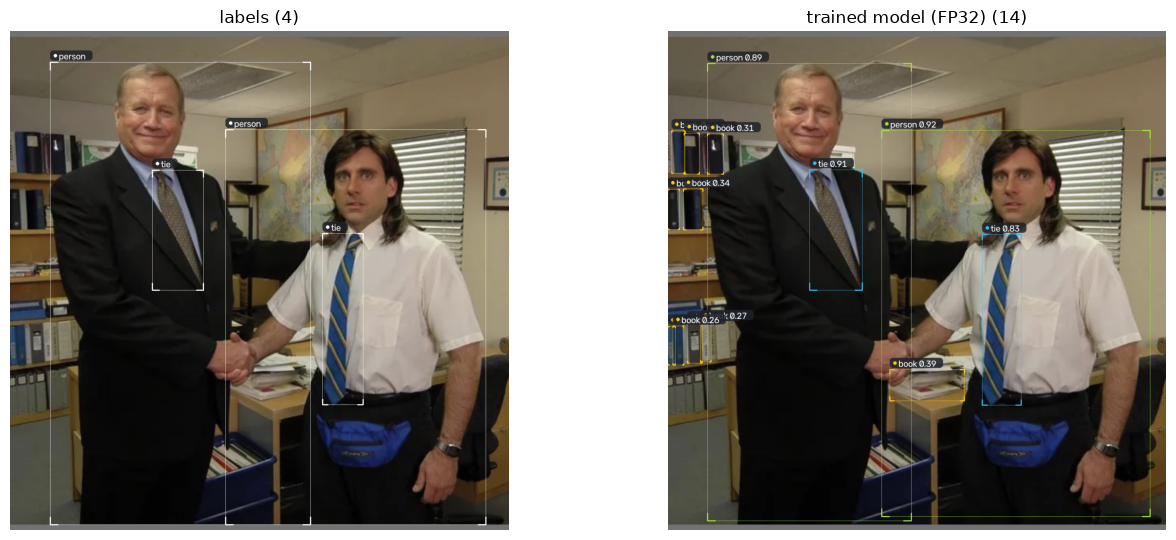

In [6]:
utils.show_predictions(data, sample, {"trained model (FP32)": utils.predict(sess_default, sample)})

# 2. Inspecting the Trained Model

Vitis AI 6.1 has no separate inspector. The same check is a quick VAISW run with the calibration skipped: VAISW splits
the model into the part the NPU runs and the parts left for the CPU, and reports it. Nothing from this run goes to the
board.

| Variable | Meaning |
|---|---|
| `VAISW_FE_PRECISION=MIXED` | INT8 with BF16 where we select it: section 5 explains the selection. |
| `VAISW_FE_MIXEDEXPLICITSELECTION` | Which part runs in the second precision, BF16: section 5.2. |
| `VAISW_QUANTIZATION_SKIP=true` | Do not calibrate: only partition and compile the model (fast). |
| `VAISW_QUANTIZATION_NBIMAGES=1` | Images to collect before VAISW starts its work: one is enough here. |
| `VAISW_QUANTIZATION_FORCE=true` | Do not reuse results that VAISW cached for an earlier model of the same structure. |
| `VAISW_SNAPSHOT_DIRECTORY` | Where the (uncalibrated, not for the board) snapshot is written. |
| `VAISW_DEBUG_GRAPHEXECUTIONREPORTPATH` | The report: each subgraph, where it runs, and its layers. |

`utils.Vaisw` runs VAISW in the Vitis AI 6.1 container, where `npu_ip/settings.sh <NPU_IP>` selects the NPU IP of the
board's bitstream.

In [7]:
vaisw = utils.Vaisw(WORKSPACE, CONTAINER, TARGET_NPU_IP)
bf16_from = [f"model__22_cv2__{i}_cv2__{i}__0_conv_Conv" for i in range(3)]   # first convolution of each box branch
bf16_from += [f"model__22_cv3__{i}_cv3__{i}__1_conv_Conv" for i in range(3)]  # second convolution of each class branch
border = ",".join(bf16_from)
precision_env = {
    "VAISW_FE_PRECISION": "MIXED",
    "VAISW_FE_MIXEDSELECTION": "BEFORE_LAST_CONV",
    "VAISW_FE_MIXEDEXPLICITSELECTION": f"FX8:AUTO:{border}|BF16:{border}:AUTO",
}


def inspection_env(out_dir):
    return {
        **precision_env,
        "VAISW_QUANTIZATION_SKIP": "true",
        "VAISW_QUANTIZATION_NBIMAGES": 1,
        "VAISW_QUANTIZATION_FORCE": "true",
        "VAISW_SNAPSHOT_DIRECTORY": out_dir / "snapshot_uncalibrated",
        "VAISW_DEBUG_GRAPHEXECUTIONREPORTPATH": out_dir / "graph_execution_report.json",
    }


out_dir = RESULT_INSPECTION / "default"
vaisw.inspect(onnx_default, sample, out_dir, inspection_env(out_dir))

Frontend: Network wrp_network FPGA support:
graph             | type | MACs             | mixed (BF16)
wrp_network_VAISW | FPGA | 14.41 G (100.0%) | 21/116 ops (3.0% MACS ratio)
wrp_network_CPU   | CPU  | 6.29 M (0.0%)    |
Frontend: simulation mode is set to bit-accurate simulation of FPGA.
2 total subgraphs:
1 VAISW (FPGA) subgraph: 99.96% of total MACs (14.42 G)
precision: mixed of FX8 (95 ops) / BF16 (21 ops, 3.00% MACs ratio)
1 Framework (CPU) subgraph

wrp_network_VAISW: NPU, 116 layers
   {'UPLOAD': 1, 'CONV': 63, 'SLICE': 16, 'ADD': 6, 'CONCAT': 13, 'MAX_POOL': 3, 'UPSAMPLE': 2, 'CAST': 6, 'DOWNLOAD': 6}

wrp_network_CPU: CPU, 25 layers
   {'RESHAPE': 8, 'CONCAT': 4, 'SIGMOID': 1, 'SOFTMAX': 1, 'TRANSPOSE': 1, 'CONV': 1, 'SLICE': 2, 'ADD': 3, 'MUL': 2, 'SUB': 1, 'DIV': 1}


Almost all of the model (in MACs) runs on the NPU, but the decoding stays on the **CPU**. The NPU has no `Reshape` or
`Transpose` for the Ultralytics tail, so the softmax and the box calculation after them cannot run there. This is
AMD's option 3 (tail on the CPU), not the full-NPU option 4 we want.

# 3. Changing the Head

**What.** We keep the decoding in the model and write it per scale, in operations the NPU has (`utils.npu_tail_forward`):

- split the 64 box channels into 4 sides of 16 bins, instead of `Reshape` + `Transpose`;
- softmax over the bins and the DFL convolution, for each side;
- a fixed 1 x 1 convolution and an anchor map turn the four distances into cx, cy, w, h, in pixels;
- the class sigmoid; the scales are joined at the very end.

**Why.** It is the same calculation, so the model output stays `[1, 84, 8400]`. The weights do not change, and the
application only has to run NMS.

In [8]:
onnx_npu_tail = utils.export_npu_tail(model_float, RESULT_EXPORT / "yolov8s_coco_npu_tail.onnx")
sess_npu_tail = utils.session(onnx_npu_tail)
utils.compare_outputs(sess_default, sess_npu_tail, data.val[:8])
scores.add_session("3. changed head (FP32)", sess_npu_tail)

8 images, largest difference: boxes 0.0011 px, scores 0.0000069


                                   P      R  mAP50  mAP50-95  person     car
1. trained model (FP32)        0.656  0.561  0.599  0.438      0.787   0.667
3. changed head (FP32)         0.656  0.561  0.599  0.438      0.787   0.667


# 4. Inspecting the Changed Model

In [9]:
out_dir = RESULT_INSPECTION / "npu_tail"
vaisw.inspect(onnx_npu_tail, sample, out_dir, inspection_env(out_dir))

Frontend: Network wrp_network FPGA support:
graph             | type | MACs             | mixed (BF16)
wrp_network_VAISW | FPGA | 14.50 G (100.0%) | 77/172 ops (3.6% MACS ratio)
wrp_network_CPU   | CPU  | 0.00 (0.0%)      |
Frontend: simulation mode is set to bit-accurate simulation of FPGA.
1 total subgraph:
1 VAISW (FPGA) subgraph: 99.99% of total MACs (14.50 G)
precision: mixed of FX8 (95 ops) / BF16 (77 ops, 3.62% MACs ratio)
0 Framework (CPU) subgraph

wrp_network_VAISW: NPU, 172 layers
   {'UPLOAD_CONSTANT': 3, 'UPLOAD': 1, 'CONV': 84, 'SLICE': 28, 'ADD': 9, 'CONCAT': 20, 'MAX_POOL': 3, 'UPSAMPLE': 2, 'CAST': 6, 'SOFTMAX': 12, 'RESHAPE': 3, 'DOWNLOAD': 1}

wrp_network_CPU: CPU, 2 layers
   {'SLICE': 1, 'RESHAPE': 1}


The whole calculation is on the NPU: one NPU subgraph and no CPU subgraph. The report's two `wrp_network_CPU` layers
have no MACs: they only give the output its final shape. They run on the board's ARM with the other format conversions
of `main.json` (section 6).

# 5. Quantization

VAISW runs the calibration images through the model, measures the range of the values in each INT8 layer and picks a
scale for each. Then the model is checked on the evaluation images, run on the simulated NPU.

## 5.1. Importing the Calibration Dataset

Calibration and evaluation both use COCO val2017, evenly spaced, and no image is in both. 16 images are within AMD's
5 to 20 for a first result.

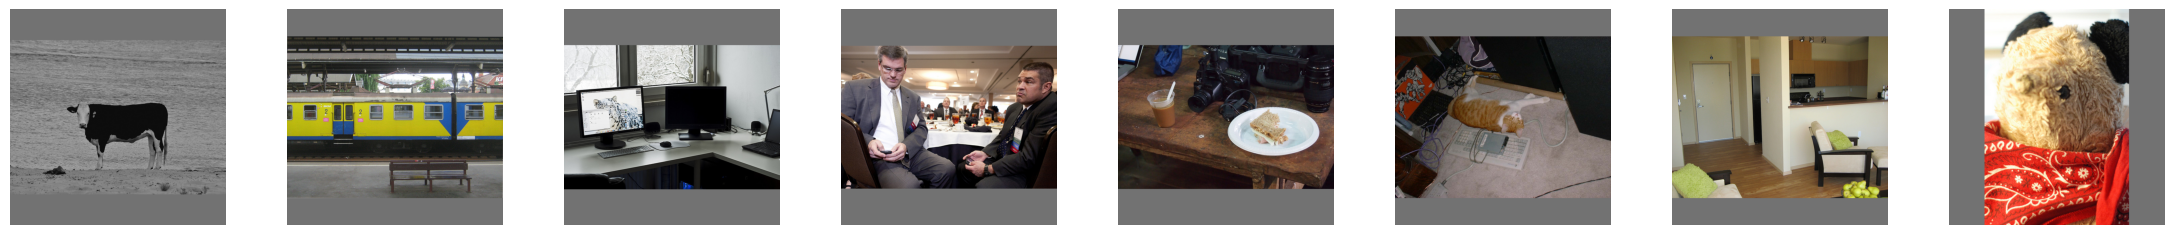

In [10]:
calib_dir = utils.link_images(data.calib, RESULT_QUANTIZATION / "calibration_images")
eval_dir = utils.link_images(data.val + [sample], RESULT_QUANTIZATION / "evaluation_images")
utils.show_images(data.calib)

## 5.2. Quantization Settings

| Variable | Meaning |
|---|---|
| `VAISW_FE_PRECISION=MIXED` | `FX8`: INT8. `MIXED`: INT8 and BF16. `BF16`: all BF16. |
| `VAISW_FE_MIXEDEXPLICITSELECTION` | The INT8 / BF16 border, `FX8:AUTO:<border>\|BF16:<border>:AUTO`: BF16 from the first convolution of each box branch and the second of each class branch on, 3.62% of the MACs. The backbone and the neck stay INT8. |
| `VAISW_QUANTIZATION_NBIMAGES` | Number of calibration images. |
| `VAISW_QUANTIZATION_BATCHACCUMULATIONALLOWED=true` | Collect the batch-1 runs until there are enough images ... |
| `VAISW_QUANTIZATION_MINIMALBATCHSIZE` | ... namely this many, then calibrate on all of them together. |
| `VAISW_QUANTIZATION_IGNORENEGATIVEVALUESONLASTLAYER=false` | Keep negative values when calibrating the last INT8 layers: they are signed. |
| `VAISW_QUANTIZATION_FORCE=true` | Calibrate again: VAISW caches its results by model *structure*, so a retrained model would otherwise get the old ones. |

In [11]:
quantization_env = {
    **precision_env,
    "VAISW_QUANTIZATION_NBIMAGES": CALIB_SIZE,
    "VAISW_QUANTIZATION_BATCHACCUMULATIONALLOWED": "true",
    "VAISW_QUANTIZATION_MINIMALBATCHSIZE": CALIB_SIZE,
    "VAISW_QUANTIZATION_IGNORENEGATIVEVALUESONLASTLAYER": "false",
    "VAISW_QUANTIZATION_FORCE": "true",
}

## 5.3. Quantizing the Model

VAISW quantizes and compiles in the same run, so this run also writes the snapshot (section 6). It takes about 30
minutes, most of it the evaluation images.

In [12]:
snapshot = RESULT_COMPILATION / "YOLOv8s_COCO.snapshot"
npu_results = RESULT_QUANTIZATION / "npu_results.npz"
compilation_env = {"VAISW_SNAPSHOT_DIRECTORY": snapshot}                     # see section 6

log = vaisw.run(RESULT_QUANTIZATION, onnx_npu_tail, calib_dir, eval_dir, npu_results, {**quantization_env, **compilation_env})
utils.print_summary(log)

Frontend: Network wrp_network FPGA support:
graph             | type | MACs             | mixed (BF16)
wrp_network_VAISW | FPGA | 14.50 G (100.0%) | 77/172 ops (3.6% MACS ratio)
wrp_network_CPU   | CPU  | 0.00 (0.0%)      |
Frontend: simulation mode is set to bit-accurate simulation of FPGA.
NPU results of 2001 images -> /home/ubuntu/DEV/AI-VITIS-TEMPLATE/src/pt_detection_yolov8s_AMDDay2026/result_quantization/npu_results.npz
1 total subgraph:
1 VAISW (FPGA) subgraph: 99.99% of total MACs (14.50 G)
precision: mixed of FX8 (95 ops) / BF16 (77 ops, 3.62% MACs ratio)
0 Framework (CPU) subgraph


## 5.4. Evaluating the Quantized Model

In [13]:
scores.add_results("5. quantized (MIXED, NPU sim.)", npu_results)

                                   P      R  mAP50  mAP50-95  person     car
1. trained model (FP32)        0.656  0.561  0.599  0.438      0.787   0.667
3. changed head (FP32)         0.656  0.561  0.599  0.438      0.787   0.667
5. quantized (MIXED, NPU sim.) 0.643  0.524  0.562  0.405      0.766   0.646


libpng warning: iCCP: extra compressed data


libpng warning: iCCP: extra compressed data


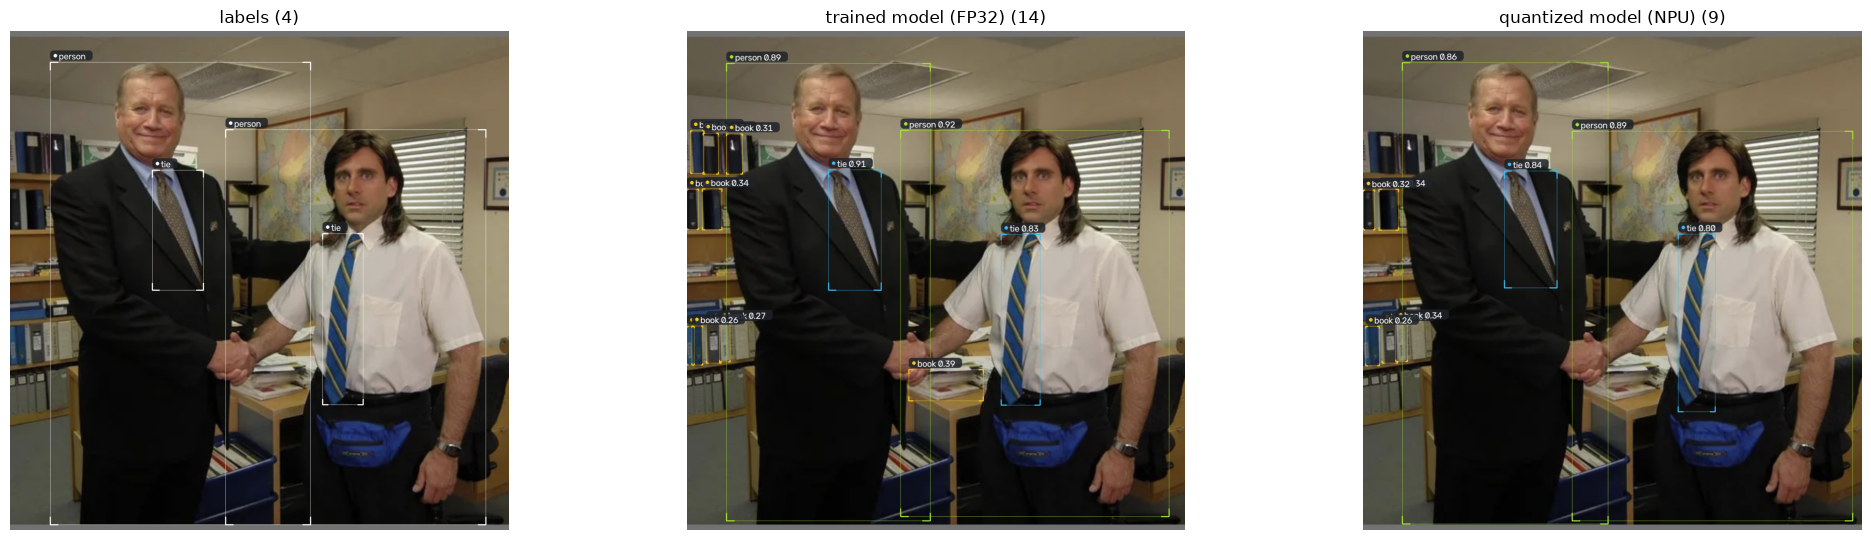

In [14]:
utils.show_predictions(data, sample, {
    "trained model (FP32)": utils.predict(sess_default, sample),
    "quantized model (NPU)": utils.saved_detections(npu_results, sample),
})

The simulation is bit-accurate for INT8 and close for BF16, so the board can differ a little. `VAISW_FE_MIXEDEXPLICITSELECTION` moves the
INT8 / BF16 border.


# 6. Compilation

The compilation turns the quantized model into a **snapshot**: the instructions and the data of the model for the NPU,
plus the description of its inputs and outputs. It ran together with the quantization in 5.3.

| Setting | Meaning |
|---|---|
| `VAISW_SNAPSHOT_DIRECTORY` | The output folder: the snapshot to copy to the board. |
| `settings.sh <NPU_IP>` | The target. It sets `VAISW_SNAPSHOT_BOARDNAME` (the NPU IP) and `VAISW_SNAPSHOT_TIMESTAMP` (its bitstream): the snapshot only loads on that bitstream. |
| `VAISW_SNAPSHOT_MODE=embedded` | Set by `settings.sh`: a snapshot for an embedded board (the VEK280), run there by VART. |

In [15]:
utils.print_snapshot(snapshot)

target: NPU IP VE2802_NPU_IP_O00_A304_M1, bitstream timestamp 0xbf6e4c01; 71 MB
main.json: EMBD_QUANTIZE -> CHANNEL_PAD -> TRANSPOSE -> CALL_SNAPSHOT -> TRANSPOSE -> CAST -> SLICE -> RESHAPE


`main.json` is the graph the board runs: one NPU call (`CALL_SNAPSHOT`) and, around it, the format conversions on the
ARM: quantize the input, and cast and reshape the output.

**On the board.** Copy the snapshot folder to the VEK280 and run it with VART (the Vitis AI runtime) from the
application: write the 640 x 640 image into the NPU input, run, read the output `[1, 84, 8400]` (cx, cy, w, h in input
pixels and 80 class scores per anchor point) and run NMS. No decoding is left for the application.